# Regression

How much does irrigation pumping reduce baseflow after accounting for weather?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

Same cleaning as the exploration notebook

In [3]:
df = pd.read_csv('../data/RRCA_baseflow.csv')

# Date is a matlab day number
df['DateTime'] = pd.to_datetime(df['Date'] - 719529, unit='D')
# some dates are a few days early (jan 29 is really feb) so round to the nearest month
df['DateTime'] = (df['DateTime'] + pd.Timedelta(days=15)).dt.to_period('M').dt.to_timestamp()
df['Year'] = df['DateTime'].dt.year
df['Month'] = df['DateTime'].dt.month

# pumping is stored as negative numbers
df['Pumping'] = df['Irrigation_pumping'] * -1

# one id per gauge location
df['Station'] = df.groupby(['x', 'y']).ngroup()

# precip = 0 is missing data
df = df[df['Precipitation'] > 0]

Train on before 1990, test on 1990-2000. One station only has data after 1995 so it gets dropped from test.

In [4]:
train = df[df['Year'] < 1990]
test = df[df['Year'] >= 1990]
test = test[test['Station'].isin(train['Station'])]

print(len(train), len(test))

9511 1604


## Model 1: just pumping

In [5]:
m1 = smf.ols('Observed ~ Pumping', data=train).fit()
m1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Observed   R-squared:                       0.011
Model:                            OLS   Adj. R-squared:                  0.011
Method:                 Least Squares   F-statistic:                     106.9
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           6.44e-25
Time:                        16:11:57   Log-Likelihood:                -53747.
No. Observations:                9511   AIC:                         1.075e+05
Df Residuals:                    9509   BIC:                         1.075e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     37.7870      0.754     50.118      0.000      36.309      39.265
Pumping      -24.2882      2.349    -10.338      0.000     -28.894     -19.683
==============================================================================
Omnibus:                    10431.140   Durbin-Watson:                   0.051
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           702407.205
Skew:                           5.756   Prob(JB):                         0.00
Kurtosis:                      43.496   Cond. No.                         3.37
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Model 2: add rain and ET

In [6]:
m2 = smf.ols('Observed ~ Pumping + Precipitation + Evapotranspiration', data=train).fit()
m2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               Observed   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     113.4
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           3.67e-72
Time:                        16:11:58   Log-Likelihood:                -53632.
No. Observations:                9511   AIC:                         1.073e+05
Df Residuals:                    9507   BIC:                         1.073e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.6421      2.842      0.578      0.563      -3.929       7.214
Pumping              -19.8119      2.591     -7.646      0.000     -24.891     -14.733
Precipitation          1.8384      0.124     14.787      0.000       1.595       2.082
Evapotranspiration    -0.5754      0.244     -2.362      0.018      -1.053      -0.098
==============================================================================
Omnibus:                    10112.340   Durbin-Watson:                   0.054
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           625554.589
Skew:                           5.485   Prob(JB):                         0.00
Kurtosis:                      41.186   Cond. No.                         88.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## Model 3: add station

In [7]:
m3 = smf.ols('Observed ~ Pumping + Precipitation + Evapotranspiration + C(Station)', data=train).fit()
print(m3.params[['Pumping', 'Precipitation', 'Evapotranspiration']])
print(m3.rsquared)

Pumping              -4.994679
Precipitation         0.806317
Evapotranspiration   -0.875558
dtype: float64
0.8061398442646432


## Model 4: add month

In [8]:
m4 = smf.ols('Observed ~ Pumping + Precipitation + Evapotranspiration + C(Station) + C(Month)', data=train).fit()
print(m4.params[['Pumping', 'Precipitation', 'Evapotranspiration']])
print(m4.rsquared)

Pumping              -0.405867
Precipitation         0.813301
Evapotranspiration   -1.159034
dtype: float64
0.8130652823060839


## Autocorrelation

Durbin-Watson in the summaries is like 0.05 (should be around 2). Checking the residuals over time

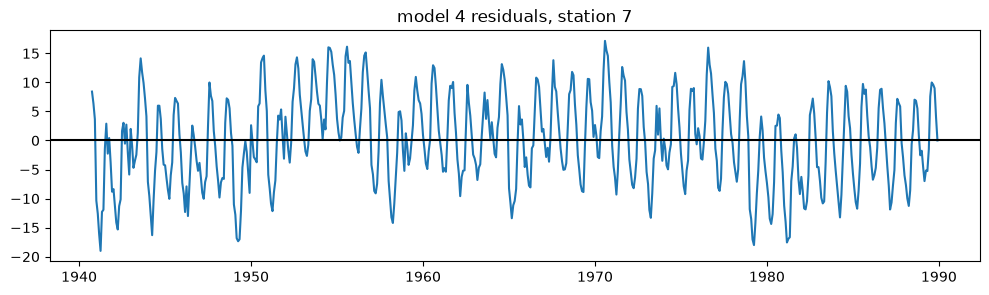

In [9]:
d = train[train['Station'] == 7]
plt.figure(figsize=(12, 3))
plt.plot(d['DateTime'], m4.resid[d.index])
plt.axhline(0, color='black')
plt.title('model 4 residuals, station 7')
plt.show()

In [10]:
r = m4.resid
prev = r.groupby(train['Station']).shift()
r.corr(prev)

np.float64(0.8778506959837165)

Residuals are 0.88 correlated with the month before so the normal p-values are way too confident. Using clustered standard errors by station to fix that.

## Comparing models

In [11]:
baseline = np.sqrt(((test['Observed'] - train['Observed'].mean()) ** 2).mean())
print('baseline rmse (just guessing the average):', baseline)

formulas = ['Observed ~ Pumping',
            'Observed ~ Pumping + Precipitation + Evapotranspiration',
            'Observed ~ Pumping + Precipitation + Evapotranspiration + C(Station)',
            'Observed ~ Pumping + Precipitation + Evapotranspiration + C(Station) + C(Month)']

for i, f in enumerate(formulas):
    m = smf.ols(f, data=train).fit()
    mc = smf.ols(f, data=train).fit(cov_type='cluster', cov_kwds={'groups': train['Station']})
    rmse = np.sqrt(((test['Observed'] - m.predict(test)) ** 2).mean())
    print('Model', i + 1)
    print('  pumping coef:', round(m.params['Pumping'], 2))
    print('  p:', round(m.pvalues['Pumping'], 4), ' clustered p:', round(mc.pvalues['Pumping'], 4))
    print('  r2:', round(m.rsquared, 3), ' test rmse:', round(rmse, 2))

baseline rmse (just guessing the average): 24.701729114400994
Model 1
  pumping coef: -24.29
  p: 0.0  clustered p: 0.0103
  r2: 0.011  test rmse: 24.04
Model 2
  pumping coef: -19.81
  p: 0.0  clustered p: 0.0225
  r2: 0.035  test rmse: 28.07
Model 3
  pumping coef: -4.99
  p: 0.0001  clustered p: 0.1823
  r2: 0.806  test rmse: 10.77
Model 4
  pumping coef: -0.41
  p: 0.7588  clustered p: 0.9188
  r2: 0.813  test rmse: 11.53


Pumping is negative every time but it shrinks a lot once station and month are in. With clustered p-values it's only significant in models 1 and 2.

Model 4 basically kills it, I think because pumping only happens in summer so month is soaking up the effect. Station is what actually matters, r2 goes from 0.03 to 0.81 and the test error gets cut in half.

## Model 5: pumping over the last year

Groundwater pumping should take a while to affect the river, so trying the total pumped over the past 12 months instead of just that month.

In [12]:
df = df.sort_values(['Station', 'DateTime'])
df['Pumping_12'] = df.groupby('Station')['Pumping'].transform(lambda x: x.rolling(12).sum())

train12 = df[df['Year'] < 1990].dropna()
test12 = df[df['Year'] >= 1990].dropna()
test12 = test12[test12['Station'].isin(train12['Station'])]

f5 = 'Observed ~ Pumping_12 + Precipitation + Evapotranspiration + C(Station) + C(Month)'
m5 = smf.ols(f5, data=train12).fit(cov_type='cluster', cov_kwds={'groups': train12['Station']})

print('coef:', m5.params['Pumping_12'])
print('clustered p:', m5.pvalues['Pumping_12'])
print('r2:', m5.rsquared)
print('test rmse:', np.sqrt(((test12['Observed'] - m5.predict(test12)) ** 2).mean()))

coef: -2.152508439805782
clustered p: 0.08684623443099658
r2: 0.832663920456377
test rmse: 10.024366920017458


-2.15 so each extra unit of pumping over a year is about 2 less baseflow. p = 0.087 so it's borderline. Test error is the lowest so far (10.0) but it's on a few less rows since the first 11 months of each station get dropped.

## Residuals

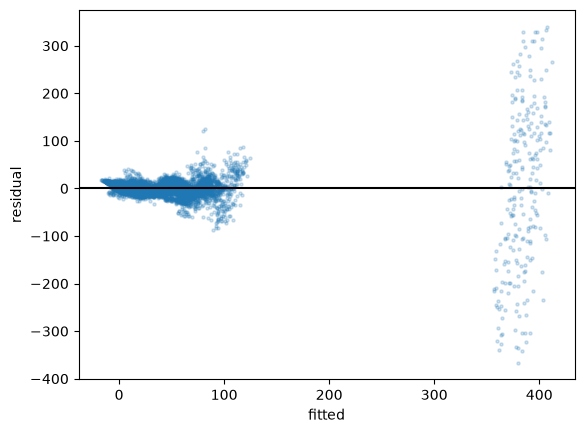

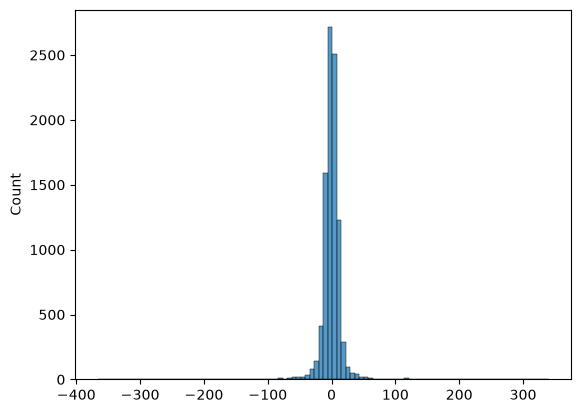

In [13]:
plt.scatter(m4.fittedvalues, m4.resid, alpha=0.2, s=5)
plt.axhline(0, color='black')
plt.xlabel('fitted')
plt.ylabel('residual')
plt.show()

sns.histplot(m4.resid, bins=100)
plt.show()

The clump way out at ~400 is one huge station and its errors are massive. Errors get bigger as fitted goes up so there's heteroscedasticity.

## Model 6: log baseflow

Trying log since baseflow is so skewed. Can't log negatives so only rows with baseflow > 0.

In [14]:
train_pos = train[train['Observed'] > 0]
test_pos = test[test['Observed'] > 0]

f6 = 'np.log(Observed) ~ Pumping + Precipitation + Evapotranspiration + C(Station) + C(Month)'
m6 = smf.ols(f6, data=train_pos).fit(cov_type='cluster', cov_kwds={'groups': train_pos['Station']})

print('coef:', m6.params['Pumping'])
print('% change per unit pumping:', (np.exp(m6.params['Pumping']) - 1) * 100)
print('clustered p:', m6.pvalues['Pumping'])
print('r2:', m6.rsquared)

coef: -0.1207930253902169
% change per unit pumping: -11.378263489459561
clustered p: 0.4615791121441055
r2: 0.8608113591125326


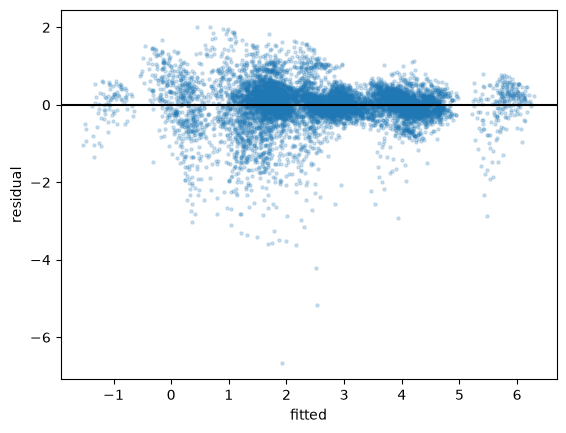

In [15]:
plt.scatter(m6.fittedvalues, m6.resid, alpha=0.2, s=5)
plt.axhline(0, color='black')
plt.xlabel('fitted')
plt.ylabel('residual')
plt.show()

In [16]:
pred = np.exp(m6.predict(test_pos))
print('log model rmse:', np.sqrt(((test_pos['Observed'] - pred) ** 2).mean()))
print('model 4 rmse on same rows:', np.sqrt(((test_pos['Observed'] - m4.predict(test_pos)) ** 2).mean()))

log model rmse: 10.62233892742863
model 4 rmse on same rows: 11.640208212739893


Residuals look a lot more even with the log. Pumping comes out to about -11% baseflow per unit but it's not significant (p = 0.47). Test error is a little better than model 4.

## Multicollinearity

Pumping and ET were correlated so checking VIF

In [17]:
X = train[['Pumping', 'Precipitation', 'Evapotranspiration']].copy()
X['const'] = 1
for i in range(3):
    print(X.columns[i], variance_inflation_factor(X.values, i))

Pumping 1.2455852755605672
Precipitation 1.008358690451039
Evapotranspiration 1.2525701827287965


All around 1.2 so it's not a problem.

## Test set

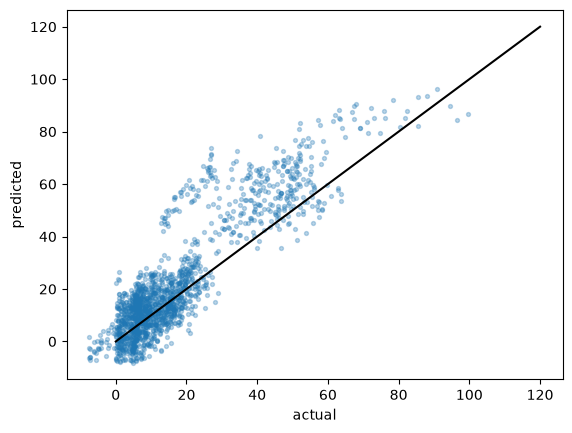

In [18]:
test = test.copy()
test['Pred'] = m4.predict(test)

plt.scatter(test['Observed'], test['Pred'], alpha=0.3, s=8)
plt.plot([0, 120], [0, 120], color='black')
plt.xlabel('actual')
plt.ylabel('predicted')
plt.show()

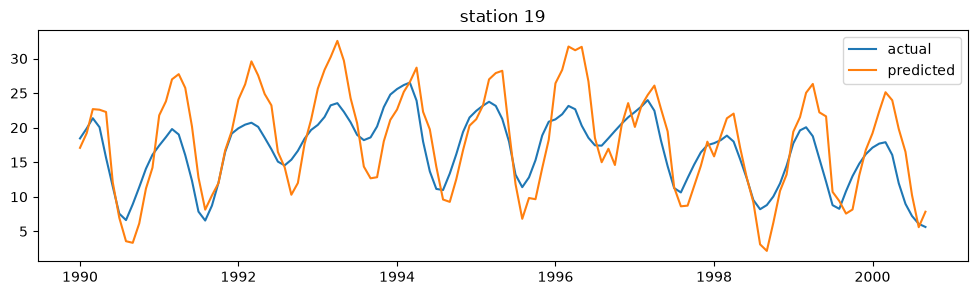

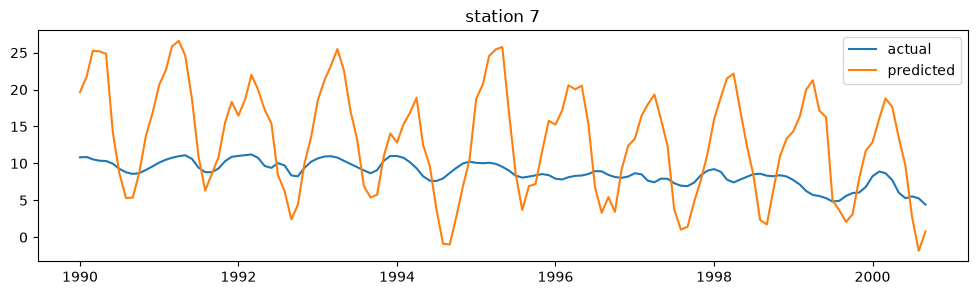

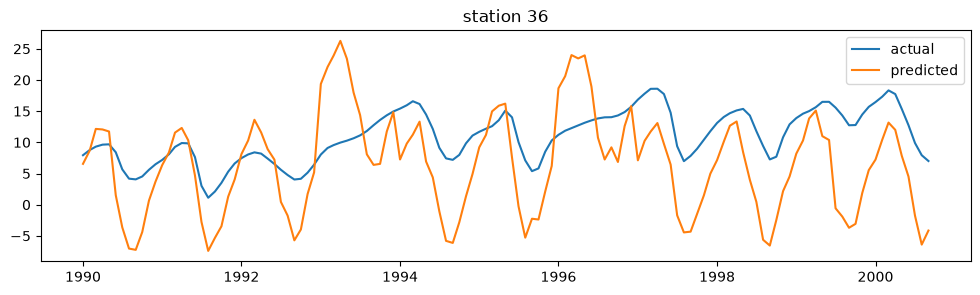

In [19]:
for s in [19, 7, 36]:
    d = test[test['Station'] == s]
    plt.figure(figsize=(12, 3))
    plt.plot(d['DateTime'], d['Observed'], label='actual')
    plt.plot(d['DateTime'], d['Pred'], label='predicted')
    plt.title('station ' + str(s))
    plt.legend()
    plt.show()

In [20]:
for s in test['Station'].unique():
    d = test[test['Station'] == s]
    print(s, round(np.sqrt(((d['Observed'] - d['Pred']) ** 2).mean()), 2))

15 7.83
38 16.41
5 7.35
42 7.95
44 6.95
27 7.49
8 36.34
28 8.03
33 7.47
19 4.62
10 20.98
7 7.89
43 7.2
36 8.12
4 7.63
9 5.49
2 17.53


It gets the up and down pattern for some stations, but the month effect is the same for every station so steady ones like station 7 get way too big of swings. Station 8 is the worst.